# 4 · The total risk picture

A 24-platform fleet over ten years, physical failures and attacks on one timeline. See
[Lesson 4](../docs/lessons/04-the-total-risk-picture.md).

In [1]:
import matplotlib.pyplot as plt

from cyberrel import plotting

plotting.use_style()

In [2]:
from cyberrel.attack_scenario_library import load_scenarios
from cyberrel.attack_to_metric_translation import combined_steady_state
from cyberrel.combined_monte_carlo_simulation import simulate_fleet
from cyberrel.system_model import navigation_system

system = navigation_system()
scenarios = list(load_scenarios().values())
fleet = simulate_fleet(system, scenarios, platforms=24, horizon=10 * 8760.0, seed=20261115)
k = fleet.kpis()
print(f"{k.failure_count} losses  MTBF {k.mtbf:,.0f} h  MTTR {k.mttr:.2f} h  A {k.availability:.5f}")
for cause in ("physical", "cyber", "both"):
    c = fleet.kpis({cause})
    print(f"  {cause:8s} {c.failure_count:5d} outages, {c.down_hours:7.1f} h down")

1885 losses  MTBF 1,114 h  MTTR 1.39 h  A 0.99875
  physical    95 outages,   383.7 h down
  cyber     1790 outages,  2238.4 h down
  both         0 outages,     0.0 h down


Simulation against the exact steady state (95 % intervals across platforms):

availability       exact 9.9870e-01  sim 9.9875e-01  [9.9866e-01, 9.9884e-01]
failure_frequency  exact 9.1911e-04  sim 8.9659e-04  [8.5715e-04, 9.3604e-04]
nmc_cyber          exact 1.1016e-03  sim 1.0647e-03  [1.0085e-03, 1.1209e-03]


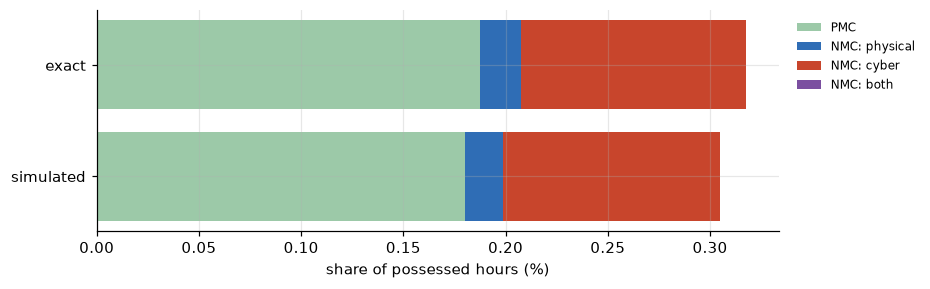

In [3]:
exact = combined_steady_state(system, scenarios)
for metric, value in (("availability", exact.availability),
                      ("failure_frequency", exact.failure_frequency),
                      ("nmc_cyber", exact.status.nmc_cyber)):
    e = fleet.estimate(metric)
    print(f"{metric:18s} exact {value:.4e}  sim {e.mean:.4e}  [{e.low:.4e}, {e.high:.4e}]")
fig = plotting.status_bars({"exact": exact.status, "simulated": fleet.status})